# Funding-carry --- final report (v8.0, the shipped product)

**Delta-neutral crypto funding carry.** Long the USDT-margined perpetual + short the equivalent spot
(or the reverse when funding is negative), so the position is market-neutral and harvests the **funding
rate** the perp pays to the spot leg. The book runs on **Binance + Bybit** (Bybit added for breadth),
rebalances **daily**, is protected by a portfolio-level **drawdown overlay**, sized under **Portfolio
Margin**, and credits **idle cash** at the T-bill rate.

This document is a **reporting artifact**, not an experiment. Numbers come from two places, always
labelled:
- **Computed live** from the canonical v8.0 run in `results/funding_carry/v8.0/` and **asserted against
  its `metrics.json`** before any figure renders (§1, §3, §5, §6).
- **Study literals** (DSR/PBO, capacity decay, regime clock) embedded verbatim with the source research
  folder cited inline (§4, §6, §7, §8). These are NOT re-run here --- see each cited notebook.

The full research program (8 shipped versions, 8 documented nulls, two honesty passes) is indexed in
`research/funding_carry/README.md`; §4 reproduces the ladder and the null ledger.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path.insert(0, str(ROOT))                      # so `from src.data import query` resolves
from src.data import query
RES = ROOT/'results'/'funding_carry'
YEAR = 365.0
NAVY,TEAL,AMBER,RED,GREY = '#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10,
                     'figure.dpi':110})
pct = FuncFormatter(lambda v,_: f'{v:.0f}%')

def newest(version):
    '''Newest run dir under results/funding_carry/<version>/ that has a metrics.json.'''
    cands = sorted(d for d in (RES/version).iterdir() if d.is_dir() and (d/'metrics.json').exists())
    if not cands: raise FileNotFoundError(version)
    return cands[-1]

RUN, RUN81 = newest('v8.0'), newest('v8.1')
MJ  = json.loads((RUN/'metrics.json').read_text())
MJ81= json.loads((RUN81/'metrics.json').read_text())
CFG = MJ['config']
print('canonical v8.0 run:', RUN.name)
print('v8.1 (capacity)  run:', RUN81.name)

# --- load canonical artifacts (strategy outputs -> read_parquet is the right path; the lake stays on query)
r  = pd.read_parquet(RUN/'returns.parquet')            # gross, net, turnover, deployed, unimmr
ad = pd.read_parquet(RUN/'attribution_daily.parquet')  # funding_pnl, basis_pnl, cost, cash
aa = pd.read_parquet(RUN/'attribution_asset.parquet')  # per venue:pair contribution
w  = pd.read_parquet(RUN/'weights.parquet')            # daily target weights, venue:pair columns
net, gross = r['net'], r['gross']
net2 = ad['funding_pnl'] + ad['basis_pnl'] + ad['cash'] - 2*ad['cost']   # 1x -> 2x cost stress

# --- rf from the lake (single read path): monthly TB3MS, decimal annual, ffill to daily / 365
rf_m = query.get('rates','fred','tb3ms','rates')['value']
def rf_daily(idx):
    key = idx.to_period('M').to_timestamp()
    return pd.Series(rf_m.reindex(key).ffill().values, index=idx)/YEAR
rf = rf_daily(net.index)

def perf(x, rfs=None):
    x = x.dropna()
    ann = x.mean()*YEAR; vol = x.std()*np.sqrt(YEAR)
    cum = (1+x).cumprod(); dd = float((cum/cum.cummax()-1).min())
    cv = float(x[x<=x.quantile(0.05)].mean())
    ann_rf = float(rfs.reindex(x.index).fillna(0.0).mean()*YEAR) if rfs is not None else 0.0
    return dict(ann=ann, vol=vol, sharpe=(ann-ann_rf)/vol, maxdd=dd, cvar95=cv)

# --- PARITY: the parquet series must reproduce metrics.json at BOTH cost multiples, or we stop.
for mult, s in [('1.0x', net), ('2.0x', net2)]:
    p = perf(s, rf); ref = MJ['results'][mult]
    assert abs(p['ann']  - ref['ann_return'])   < 1e-4, (mult,'ann')
    assert abs(p['sharpe'] - ref['sharpe'])     < 2e-3, (mult,'sharpe')
    assert abs(p['maxdd']- ref['max_drawdown']) < 1e-4, (mult,'maxdd')
    assert abs(p['cvar95']-ref['cvar95'])       < 1e-4, (mult,'cvar95')
print('PARITY OK -- recomputed net / Sharpe (rf-adjusted) / maxDD / CVaR95 match metrics.json (1x & 2x)')
print('period:', MJ['period'][0], '->', MJ['period'][1], '|', len(net), 'trading days |',
      'full-sample rf mean %.2f%%/yr' % (rf.mean()*YEAR*100))

canonical v8.0 run: 20260707T143037Z
v8.1 (capacity)  run: 20260707T143120Z
PARITY OK -- recomputed net / Sharpe (rf-adjusted) / maxDD / CVaR95 match metrics.json (1x & 2x)
period: 2021-01-01 -> 2026-05-31 | 1947 trading days | full-sample rf mean 3.31%/yr


## 1. Executive summary

The product is a **delta-neutral funding-carry** book: **Binance + Bybit** breadth, **daily** rebalance,
**drawdown-overlay** protected, **Portfolio-Margin** sized, and **cash-yielding** on idle days. It is
market-neutral by construction (per-name long-perp / short-spot legs net to ~0 directional exposure),
so its P&L is the funding rate minus basis, costs, and the overlay's opportunity cost --- and its daily
beta to crypto is ~0.

**Every Sharpe here is rf-adjusted** — (E[r] − E[rf]) / vol(r), rf = FRED 3-month T-bill from the
lake; ratios that ignore rf are not Sharpe ratios and are not shown. The **1x Sharpe of 5.07 is
deflation-robust** (DSR ~1.0 out to N=1000 trials, `multiple_testing/`; that pass used the
near-identical excess-series formula — verdicts unaffected); the **2x-cost Sharpe of 3.48 is a
cost-stress figure only** --- it does NOT clear the deflation bar and must never be quoted as the
headline.

In [2]:
r1, r2 = MJ['results']['1.0x'], MJ['results']['2.0x']
claim = pd.DataFrame({
 'value': [
   f"{r1['ann_return']*100:.2f}%/yr",
   f"{r1['sharpe']:.2f}",
   f"{r2['sharpe']:.2f}",
   f"{r1['ann_vol']*100:.2f}%",
   f"{r1['max_drawdown']*100:.2f}%",
   f"{r1['ann_turnover']:.1f}x/yr",
   f"{r1['avg_names_held']:.0f}",
   f"{r1['pct_days_deployed']*100:.0f}%",
   "~$20-30M -> ~$40M+ (v8.1)",
   "~0",
 ]}, index=[
   'Net return (incl. cash), 1x cost',
   'Sharpe (rf-adjusted), 1x  [DEFLATION-ROBUST headline]',
   'Sharpe (rf-adjusted), 2x cost  [STRESS ONLY -- not deflation-robust]',
   'Annualised volatility',
   'Max drawdown',
   'Turnover',
   'Avg names held',
   'Days deployed (overlay in)',
   'Capacity ceiling (v8.0 -> v8.1 full book)',
   'Daily beta to crypto',
 ])
claim.index.name = 'CLAIM SHEET  (v8.0, %s -> %s)' % (MJ['period'][0], MJ['period'][1])
print(claim.to_string())

                                                                                          value
CLAIM SHEET  (v8.0, 2021-01-01 -> 2026-05-31)                                                  
Net return (incl. cash), 1x cost                                                      10.68%/yr
Sharpe (rf-adjusted), 1x  [DEFLATION-ROBUST headline]                                      5.07
Sharpe (rf-adjusted), 2x cost  [STRESS ONLY -- not deflation-robust]                       3.48
Annualised volatility                                                                     1.45%
Max drawdown                                                                             -0.88%
Turnover                                                                               11.8x/yr
Avg names held                                                                              146
Days deployed (overlay in)                                                                  78%
Capacity ceiling (v8.0 -> v8.1 full book

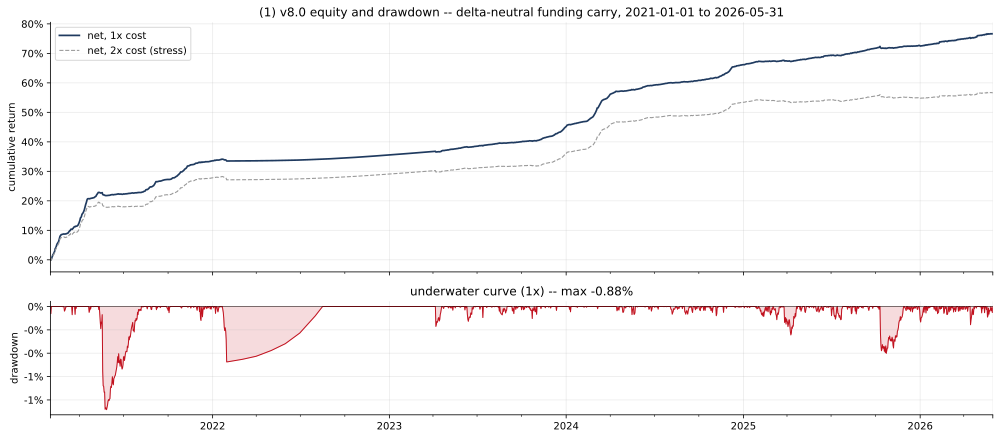

In [3]:
# Headline: equity + underwater (net, 1x cost).  2x drawn dashed for scale.
eq1 = (1+net).cumprod(); eq2 = (1+net2).cumprod()
dd1 = (eq1/eq1.cummax()-1)*100
fig,(a1,a2) = plt.subplots(2,1, figsize=(14,6.2), height_ratios=[2.2,1], sharex=True)
((eq1-1)*100).plot(ax=a1, color=NAVY, lw=1.7, label='net, 1x cost')
((eq2-1)*100).plot(ax=a1, color=GREY, lw=1.1, ls='--', label='net, 2x cost (stress)')
a1.yaxis.set_major_formatter(pct); a1.set_ylabel('cumulative return')
a1.legend(loc='upper left'); a1.set_title('(1) v8.0 equity and drawdown -- delta-neutral funding carry, %s to %s' % (MJ['period'][0], MJ['period'][1]))
dd1.plot(ax=a2, color=RED, lw=1.0); a2.fill_between(dd1.index, dd1.values, 0, color=RED, alpha=0.15)
a2.yaxis.set_major_formatter(pct); a2.set_ylabel('drawdown'); a2.axhline(0,color='k',lw=0.5)
a2.set_title('underwater curve (1x) -- max %.2f%%' % (dd1.min()))
plt.tight_layout(); plt.show()

## 2. Strategy specification (the frozen stack)

Each layer below was added by one version of the ladder (§4) and then frozen. The configuration is
printed verbatim from `config/strategies/funding_carry/v8.yaml` beneath the description.

- **Signal.** Per name, EWMA of the funding APR, **half-life 7 days**. Enter when smoothed APR
  >= **8%** (`theta_in`), keep while >= **2%** (`theta_keep`) --- a hysteresis band (Layer D, v1) that
  collapses turnover versus a single threshold. Gates are **absolute**, not rf-indexed: indexing them
  to rf was tested and **rejected** (`rf_gates/`, the 8th null).
- **Vetoes** (hard drop, evaluated point-in-time): `funding_vol` > 0.75, negative-funding frequency
  `neg_freq` > 0.40, `basis` > 0.01 (the basis-blowout veto, v2.1 --- the single biggest Sharpe lift),
  and minimum `age` >= 15 days (young-listing cohort is toxic, v6).
- **Sizing.** 50/50 blend of inverse basis-vol and inverse 60-day CVaR (v3.0 + v6.1), CVaR winsorised
  at 0.90, with a **no-trade band of 0.5** (v3.1) that denoises the tilt and caps turnover.
- **Overlay.** Portfolio-level "shadow" drawdown switch (v4): exit to cash when the shadow book's own
  drawdown breaches its expanding **p15**, re-enter at **p50**, on a **252-day** lookback. It is the
  entire reason 2022 is flat rather than negative.
- **Margin.** Per-venue **Portfolio Margin**, deploy ratio **1.0** (validated safe in v5: worst-case
  daily uniMMR >> the 1.05 liquidation floor). Collateral/MMR haircuts per the config maps.
- **Cash.** Idle capital (overlay fully out) credited at 3M T-bill x **capture 0.75** (v8).
- **Universe.** Resolved from the config registry: Binance **all** perps + Bybit **breadth**
  (Bybit-only names). Survivorship-clean --- delisted names are included (§3).

In [4]:
print(open(ROOT/'config'/'strategies'/'funding_carry'/'v8.yaml').read())

# Funding-carry v8.0 â€” IDLE-CASH YIELD (accounting correction, not alpha).
# Strategy = v7.0 (multi-venue breadth); the ONE change is the `cash` block: idle cash (which is
# binary â€” the v4 overlay fully out, 21% of days, ~all of 2022 + early 2023) is credited at the
# 3M T-bill rate Ã— capture. Research (v8_cash_yield/cash_yield.ipynb): +0.5-0.6%/yr, Calmar up for
# all books, 2022 flips ~0% -> +2.0%; maxDD unchanged for this book (its maxDD is in a deployed
# window). Sharpe is computed as (E[r] âˆ’ E[rf]) / vol(r) everywhere â€” the rf path comes with
# this config, and ratios that ignore rf are not reported (they are not Sharpe ratios).
# rf comes from the lake: fred/tb3ms (actual FRED observations via the official API â€” backfill
# with FRED_API_KEY set: uv run python -m scripts.backfill --source fred, then normalize).
# capture 0.75 = on-venue Simple-Earn-style capture; off-venue T-bills during overlay-out â‰ˆ 1.0.
#   uv run python -m src.strategies.funding_carry.v8.backtes

## 3. Data

**The lake.** Four crypto venues are connected (Binance, Bybit, OKX, Hyperliquid) plus CME futures and
FRED rates, all read through the single path `src.data.query`. Only **Binance + Bybit** are traded:
both are backfillable to 2021 including **delisted** perps, so the universe is **survivorship-clean**
(a book that only ever saw survivors would overstate carry --- delisted names ran materially hotter
funding, `universe/survivorship_audit.ipynb`). OKX and Hyperliquid funding is forward-only / thin and
is not traded (`v7_cross_venue/`, `bybit`-data notes). rf is FRED `tb3ms` (3M T-bill).

The coverage figure counts, per venue per day, the perps whose `[first, last]` funding-rate span (from
`query.coverage`) brackets that day --- i.e. the point-in-time tradeable universe, delistings and all.

binance :  466 perps ever in lake |   91 delisted (last < 2026-05-01) |  375 still live | registry/traded universe = 466
bybit   :  342 perps ever in lake |   37 delisted (last < 2026-05-01) |  305 still live | registry/traded universe = 115
581 venue:pair columns in the book = 581 (binance all + bybit breadth)


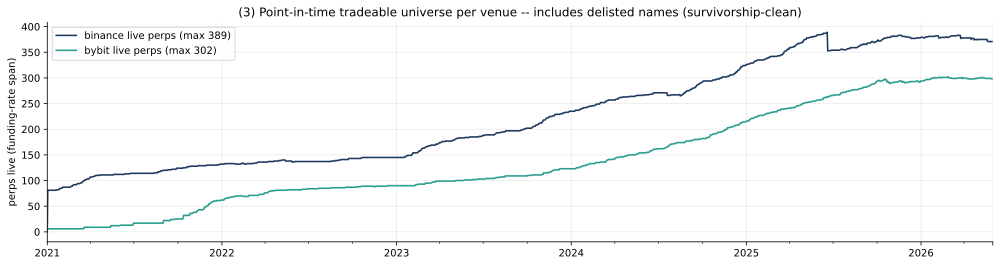

In [5]:
cov = {v: query.coverage('perps', v, 'funding_rate') for v in ('binance','bybit')}
grid = pd.date_range(MJ['period'][0], MJ['period'][1], freq='D')
cut  = grid.max() - pd.Timedelta(days=30)
live = pd.DataFrame({v: [int(((c['first']<=d) & (c['last']>=d)).sum()) for d in grid]
                     for v, c in cov.items()}, index=grid)
# registry (traded) universe sizes + lake survivorship counts
uni = {v: len(CFG['universe'][v]) for v in ('binance','bybit')}
for v,c in cov.items():
    tot = len(c); deldn = int((c['last'] < cut).sum())
    print(f"{v:8s}: {tot:4d} perps ever in lake | {deldn:4d} delisted (last < {cut.date()}) | "
          f"{tot-deldn:4d} still live | registry/traded universe = {uni[v]}")
print('581 venue:pair columns in the book =', sum(uni.values()), '(binance all + bybit breadth)')

fig, ax = plt.subplots(figsize=(14,3.8))
live['binance'].plot(ax=ax, color=NAVY, lw=1.6, label=f"binance live perps (max {live['binance'].max()})")
live['bybit'].plot(ax=ax, color=TEAL, lw=1.6, label=f"bybit live perps (max {live['bybit'].max()})")
ax.set_ylabel('perps live (funding-rate span)'); ax.legend(loc='upper left')
ax.set_title('(3) Point-in-time tradeable universe per venue -- includes delisted names (survivorship-clean)')
plt.tight_layout(); plt.show()

**Survivorship (live counts above + finding from `universe/survivorship_audit.ipynb`).** The lake
retains **delisted** perps, not just survivors: the coverage cell shows the registry trades **all 466**
Binance perps even though only ~375 are still live within the backtest window --- the gap *is* the
retained delisted names, and the same holds for Bybit. That matters because the audit found delisted
names ran **median funding ~8%** versus ~**0.8%** for survivors: a survivor-only book would understate
both the harvestable carry and the tail risk those names carried before they delisted. They are kept in
and the **basis / age / funding-vol vetoes** do the risk control instead of exclusion. Bybit adds its
**Bybit-only breadth** names on top of the Binance set (v7 cross-venue).

## 4. Provenance --- how this book was built (and what was rejected)

Two ledgers. The **version ladder** is the sequence of shipped changes, each frozen once validated;
the **null ledger** is the eight documented dead-ends. Headline Sharpes across ladder rows are on
**evolving universes** (majors -> broad -> cross-venue) and are *not* directly comparable row-to-row
--- only v7/v8 are on the final Binance+Bybit universe. Every row cites its folder under
`research/funding_carry/`.

In [6]:
ladder = pd.DataFrame([
 ('v0  baseline',            'net edge on 5 majors, after cost',        'FAILS gate: net +1.6% / Sh 0.84 (1x); churn 54x is the killer', 'v0_baseline/'),
 ('v1  Layer-D hysteresis',  'EWMA-mean exit (theta_in/theta_keep)',    'turnover collapses; knobs robust in time (corr 0.83)',          'v1_layer_d/'),
 ('v2.1 basis veto',         'cross-sectional selection + basis-blowout','Sharpe 1.5 -> 5.4, DD -10% -> -3% (the biggest single lift)',   'v2_selection/'),
 ('v3.0 inv-basis-vol size', 'risk-aware weighting vs equal weight',    'Sharpe 5.4 -> 5.75',                                            'v3_sizing/'),
 ('v3.1 no-trade band',      'band 0.5 denoises the tilt',              'Sharpe 6.32, 2x 3.62, turnover back to ~20x (best diagonal)',   'v3_sizing/'),
 ('v4  drawdown overlay',    'portfolio shadow-DD switch (sits out 2022)','maxDD -2.8% -> -0.9%, Calmar 3.5 -> 11; beats placebo',        'v4_drawdown_overlay/'),
 ('v5  margin model',        'returns per $ equity; PM safety',         'deploy 1.0 under PM validated (worst uniMMR >> 1.05 floor)',     'v5_capital_efficiency/'),
 ('v6.0/6.1 refinements',    'min-age veto (15d) + CVaR-blend sizing',  '2x Sharpe 4.85 -> 5.15/5.18, turnover 13 -> 11.8x',             'v6_selection_refinements/'),
 ('v7.0/7.1 cross-venue',    'add Bybit venue:pair (breadth / full book)','OOS 2x 5.36 -> 6.05; net 10.23%, Sh 7.00, 2x 5.40',            'v7_cross_venue/'),
 ('v8.0/8.1 cash yield',     'credit idle cash at T-bill; excess-Sharpe','net 10.68%, excess Sh 4.99 (1x) / 3.43 (2x), maxDD -0.88%',     'v8_cash_yield/'),
], columns=['version','change','headline','folder'])
print('VERSION LADDER  (research/funding_carry/)'); print(ladder.to_string(index=False))

VERSION LADDER  (research/funding_carry/)
                version                                     change                                                      headline                    folder
           v0  baseline           net edge on 5 majors, after cost FAILS gate: net +1.6% / Sh 0.84 (1x); churn 54x is the killer              v0_baseline/
 v1  Layer-D hysteresis       EWMA-mean exit (theta_in/theta_keep)          turnover collapses; knobs robust in time (corr 0.83)               v1_layer_d/
        v2.1 basis veto  cross-sectional selection + basis-blowout   Sharpe 1.5 -> 5.4, DD -10% -> -3% (the biggest single lift)             v2_selection/
v3.0 inv-basis-vol size       risk-aware weighting vs equal weight                                            Sharpe 5.4 -> 5.75                v3_sizing/
     v3.1 no-trade band                 band 0.5 denoises the tilt   Sharpe 6.32, 2x 3.62, turnover back to ~20x (best diagonal)                v3_sizing/
   v4  drawdown overlay port

In [7]:
nulls = pd.DataFrame([
 ('Top-K-by-funding selection', 'concentrates into a few high-funding names -> basis risk; the win was the veto, not picking', 'v2_selection/'),
 ('Layer G factor sizing',      'covariance/min-var/tilt all lose to the diagonal v3.1 -- the factor downside is already vetoed', 'v3_sizing/factor_sizing.ipynb'),
 ('Layer H shrinkage',          "winner's curse is a LEVEL bias not a RANKING one; rank-IC unchanged, backtest slightly worse",   'estimation_hygiene/shrinkage.ipynb'),
 ('Per-asset drawdown overlay', 'name-level DD is idiosyncratic basis noise -> whipsaw; signal only tradeable at the aggregate',  'v4_drawdown_overlay/'),
 ('Vol-regime scaling',         'price vol is orthogonal to carry drawdown (rho 0.07); zero overlap with the v4 overlay',         'v6_selection_refinements/vol_regime_scaling.ipynb'),
 ('Venue-selection switching',  'spread half-life ~0.7d lives in veto-dropped names; switching doubles turnover, halves 2x-Sharpe','v7_cross_venue/'),
 ('Daily funding-timing / prediction','O-day timing oracle is -11% net of cost; funding-prediction models add nothing over EWMA','flat_years/'),
 ('rf-indexed gates (v9 cand.)','flat-year supply compresses as rf rises -> gate exceeds the whole distribution; evicts 2024 names','rf_gates/'),
], columns=['null (rejected)','why it died','folder'])
print('NULL LEDGER -- 8 documented dead-ends'); print(nulls.to_string(index=False))

NULL LEDGER -- 8 documented dead-ends
                  null (rejected)                                                                                       why it died                                            folder
       Top-K-by-funding selection       concentrates into a few high-funding names -> basis risk; the win was the veto, not picking                                     v2_selection/
            Layer G factor sizing    covariance/min-var/tilt all lose to the diagonal v3.1 -- the factor downside is already vetoed                     v3_sizing/factor_sizing.ipynb
                Layer H shrinkage      winner's curse is a LEVEL bias not a RANKING one; rank-IC unchanged, backtest slightly worse                estimation_hygiene/shrinkage.ipynb
       Per-asset drawdown overlay     name-level DD is idiosyncratic basis noise -> whipsaw; signal only tradeable at the aggregate                              v4_drawdown_overlay/
               Vol-regime scaling            price v

**Discipline (cited).** Each step was **preregistered** (question + expected result before the
run), validated **temporally out-of-sample** (a later window it was not tuned on), and checked for
**engine<->lab parity** (`lab.py` reproduces the production `engine.run` to 1e-6). The whole ladder
was then put through a **multiple-testing honesty pass** (`multiple_testing/dsr_pbo.ipynb`): Deflated
Sharpe Ratio + PBO on **both** the raw and the excess-of-rf bases, against a logged trial ledger of
**~143 configurations** (the full program including the regime-atlas companion is ~146). Key results
(embedded literals; see the notebook): on the **excess-of-rf** basis the **1x** DSR is ~**1.000** for
v8.0's 4.99 against a *real* expected-max of ~2.5 --- **deflation-robust to N=1000**; at **2x** every
book falls below the ~3.98 expected-max (v8.0 best 3.43, DSR **0.05**) --- a **level** shortfall, not
selection-overfitting (excess **PBO 0.03**, and the in-sample-best config is unchanged raw<->excess).

## 5. Results (canonical run, computed live)

Everything in this section is recomputed from the run's parquet series and was asserted equal to
`metrics.json` in the setup cell. `net` includes the cash credit; the 2x column stresses **costs only**
(funding + basis + cash - 2x cost).

In [8]:
def col(s):
    p = perf(s, rf)
    return {'net ann':f"{p['ann']*100:.2f}%", 'Sharpe':f"{p['sharpe']:.2f}",
            'ann vol':f"{p['vol']*100:.2f}%",
            'maxDD':f"{p['maxdd']*100:.2f}%", 'CVaR95 (daily)':f"{p['cvar95']*100:.3f}%"}
M = pd.DataFrame({'1x cost': col(net), '2x cost (stress)': col(net2)}).T
M['turnover']      = [f"{MJ['results']['1.0x']['ann_turnover']:.1f}x", f"{MJ['results']['2.0x']['ann_turnover']:.1f}x"]
M['avg names']     = [f"{MJ['results']['1.0x']['avg_names_held']:.0f}", f"{MJ['results']['2.0x']['avg_names_held']:.0f}"]
M['days deployed'] = [f"{MJ['results']['1.0x']['pct_days_deployed']*100:.0f}%"]*2
print('FULL METRICS  (Sharpe = (E[r] - E[rf]) / vol(r), everywhere)')
print(M.to_string())

FULL METRICS  (Sharpe = (E[r] - E[rf]) / vol(r), everywhere)
                 net ann Sharpe ann vol   maxDD CVaR95 (daily) turnover avg names days deployed
1x cost           10.68%   5.07   1.45%  -0.88%        -0.066%    11.8x       146           78%
2x cost (stress)   8.43%   3.48   1.47%  -1.46%        -0.093%    11.8x       146           78%


In [9]:
# Per-year: net, rf, excess return, and the (rf-adjusted) Sharpe -- the front-loaded profile.
yr = net.index.year
rows = {}
for y in sorted(set(yr)):
    m = yr == y
    pn = perf(net[m], rf); n_ann = pn['ann']; rf_ann = rf[m].mean()*YEAR
    rows[y] = {'days':int(m.sum()), 'net %':round(n_ann*100,2), 'rf %':round(rf_ann*100,2),
               'excess %':round((n_ann-rf_ann)*100,2), 'Sharpe':round(pn['sharpe'],2)}
PY = pd.DataFrame(rows).T
print('PER-YEAR  (net incl. cash; excess = net - rf; rf = FRED tb3ms)')
print(PY.to_string())
print('\nfull-sample: net %.2f%%  rf %.2f%%  excess %.2f%%/yr'
      % (net.mean()*YEAR*100, rf.mean()*YEAR*100, (net.mean()-rf.mean())*YEAR*100))

PER-YEAR  (net incl. cash; excess = net - rf; rf = FRED tb3ms)
       days  net %  rf %  excess %  Sharpe
2021  335.0  31.56  0.04     31.52   11.23
2022  365.0   1.49  2.03     -0.54   -1.70
2023  365.0   6.81  5.07      1.74    2.63
2024  366.0  13.53  4.97      8.57    7.89
2025  365.0   3.83  4.07     -0.24   -0.36
2026  151.0   5.59  3.60      1.99    2.15

full-sample: net 10.68%  rf 3.31%  excess 7.37%/yr


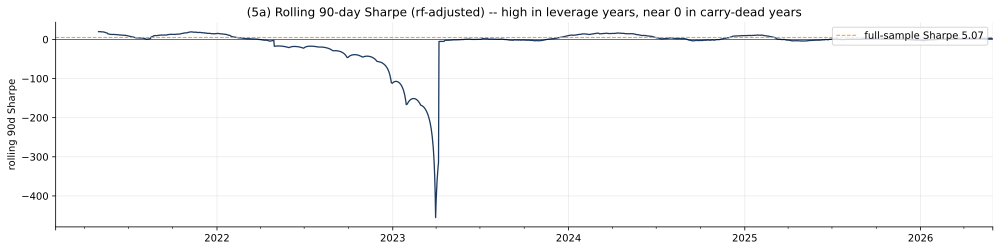

In [10]:
# Rolling 90d Sharpe (annualised, rf-adjusted: (E[r]-E[rf])/vol(r) on the window).
roll = ((net.rolling(90).mean() - rf.rolling(90).mean())*YEAR) / (net.rolling(90).std()*np.sqrt(YEAR))
fig,ax = plt.subplots(figsize=(14,3.6))
roll.plot(ax=ax, color=NAVY, lw=1.3)
ax.axhline(0, color='k', lw=0.5); ax.axhline(MJ['results']['1.0x']['sharpe'], color=AMBER, lw=1.0, ls='--',
          label=f"full-sample Sharpe {MJ['results']['1.0x']['sharpe']:.2f}")
ax.set_ylabel('rolling 90d Sharpe'); ax.legend(loc='upper right')
ax.set_title('(5a) Rolling 90-day Sharpe (rf-adjusted) -- high in leverage years, near 0 in carry-dead years')
plt.tight_layout(); plt.show()

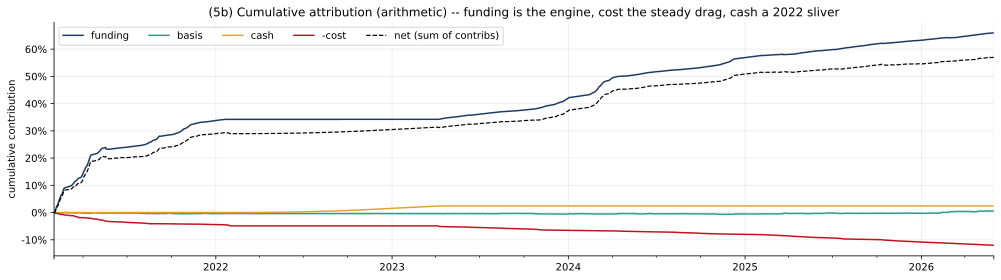

final arithmetic contributions (%):
funding    65.97
basis       0.59
cash        2.43
cost       12.01


In [11]:
# Cumulative arithmetic attribution: funding / basis / cash / -cost  (sum of daily contributions).
cum = pd.DataFrame({'funding':ad['funding_pnl'], 'basis':ad['basis_pnl'],
                    'cash':ad['cash'], '-cost':-ad['cost']}).cumsum()*100
fig,ax = plt.subplots(figsize=(14,4))
for c,col_ in [('funding',NAVY),('basis',TEAL),('cash',AMBER),('-cost',RED)]:
    cum[c].plot(ax=ax, color=col_, lw=1.5, label=c)
(net.cumsum()*100).plot(ax=ax, color='k', lw=1.2, ls='--', label='net (sum of contribs)')
ax.yaxis.set_major_formatter(pct); ax.set_ylabel('cumulative contribution'); ax.legend(loc='upper left', ncol=5)
ax.set_title('(5b) Cumulative attribution (arithmetic) -- funding is the engine, cost the steady drag, cash a 2022 sliver')
plt.tight_layout(); plt.show()
print('final arithmetic contributions (%):')
print((pd.DataFrame({'funding':ad['funding_pnl'],'basis':ad['basis_pnl'],'cash':ad['cash'],'cost':ad['cost']}).sum()*100).round(2).to_string())

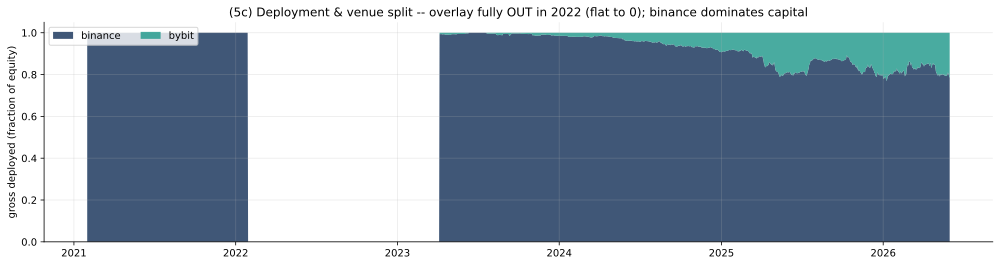

mean capital share (v8.0 breadth): binance 0.728  bybit 0.050  idle 0.222


In [12]:
# Deployment + venue split: summed target weight per venue (stacked). Total = deployed fraction (<=1).
ven = {v: w[[c for c in w.columns if c.startswith(v+':')]].sum(axis=1) for v in ('binance','bybit')}
V = pd.DataFrame(ven)
fig,ax = plt.subplots(figsize=(14,3.8))
ax.stackplot(V.index, V['binance'].values, V['bybit'].values, labels=['binance','bybit'],
             colors=[NAVY,TEAL], alpha=0.85)
ax.set_ylim(0,1.05); ax.set_ylabel('gross deployed (fraction of equity)'); ax.legend(loc='upper left', ncol=2)
ax.set_title('(5c) Deployment & venue split -- overlay fully OUT in 2022 (flat to 0); binance dominates capital')
plt.tight_layout(); plt.show()
cs = MJ['venues']['capital_share_mean']
print('mean capital share (v8.0 breadth): binance %.3f  bybit %.3f  idle %.3f'
      % (cs['binance'], cs['bybit'], 1-cs['binance']-cs['bybit']))

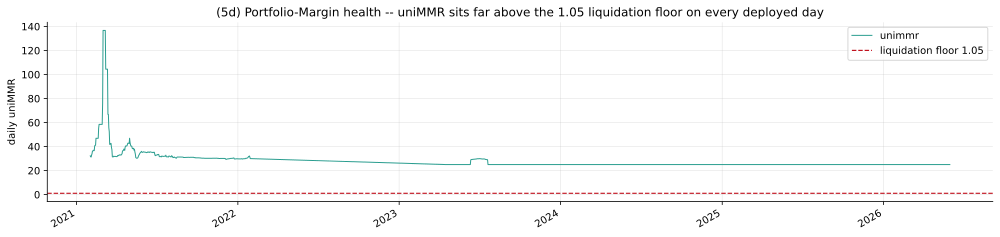

per-venue uniMMR (min / median): {'binance': (25.0, 28.3), 'bybit': (25.0, 25.0)}


In [13]:
# Portfolio uniMMR (higher = safer) with the liquidation floor.
um = r['unimmr'].dropna()
fig,ax = plt.subplots(figsize=(14,3.4))
um.plot(ax=ax, color=TEAL, lw=1.0)
ax.axhline(MJ['margin']['liq_threshold'], color=RED, lw=1.2, ls='--',
           label=f"liquidation floor {MJ['margin']['liq_threshold']}")
ax.set_ylabel('daily uniMMR'); ax.legend(loc='upper right')
ax.set_title('(5d) Portfolio-Margin health -- uniMMR sits far above the 1.05 liquidation floor on every deployed day')
plt.tight_layout(); plt.show()
mv = MJ['margin']['venues']
print('per-venue uniMMR (min / median):',
      {k: (v['unimmr_min'], v['unimmr_median']) for k,v in mv.items()})

In [14]:
# Top-15 net contributors (full sample, arithmetic net_pnl in %).
top = aa.sort_values('net_pnl', ascending=False).head(15).copy()
T15 = pd.DataFrame({
  'pct days held': (top['pct_days_held']*100).round(1),
  'mean APR held': (top['mean_apr_held']*100).round(1),
  'net contrib %': (top['net_pnl']*100).round(3),
  'funding %':     (top['funding_pnl']*100).round(3),
  'basis %':       (top['basis_pnl']*100).round(3),
  'hit rate':      top['hit_rate'].round(3),
})
print('TOP-15 NET CONTRIBUTORS  (venue:pair, full sample)'); print(T15.to_string())
print('\ntop-15 share of total net_pnl: %.1f%%  |  positive-contributor names: %d / %d'
      % (top['net_pnl'].sum()/aa['net_pnl'].sum()*100, (aa['net_pnl']>0).sum(), (aa['net_pnl'].abs()>0).sum()))

TOP-15 NET CONTRIBUTORS  (venue:pair, full sample)
                  pct days held  mean APR held  net contrib %  funding %  basis %  hit rate
symbol                                                                                     
binance:btcusdt            50.9           16.8          2.181      2.518   -0.007     0.809
binance:ethusdt            58.5           16.7          2.131      2.443   -0.014     0.792
binance:eosusdt            50.2           20.5          1.520      1.801   -0.024     0.656
binance:bchusdt            29.7           22.3          1.309      1.490   -0.003     0.714
binance:adausdt            47.2           19.0          1.161      1.294    0.040     0.715
binance:dashusdt           63.1           16.0          1.157      1.317   -0.009     0.640
binance:ltcusdt            51.9           17.9          1.052      1.271   -0.013     0.770
binance:zecusdt            52.4           17.8          0.856      1.022   -0.047     0.659
binance:atomusdt           27

## 6. Regime profile & correlations

Carry is a **regime-gated bet on leverage demand**. When traders lever long, perps pay a large funding
premium and the book harvests it; when leverage unwinds, funding collapses to ~0 and --- **by design**
--- the book earns roughly **rf** (overlay out, cash credited) rather than reaching for a thin, risky
premium. The excess-of-rf return is therefore **front-loaded** into the leverage years, and this is a
feature, not a defect: the flat years are the overlay correctly declining to bear tail risk for a
sub-rf premium.

**Regime clock (median cross-sectional 30d funding APR; literals, `research/regime_atlas/atlas.ipynb`):**
~**40%** (2021 leverage euphoria) -> ~**0%** (2022 deleveraging) -> ~**0% / below-rf** (2023 low-carry
grind) -> ~**16%** (2024 leverage re-rating) -> ~**3%** (2025 carry-dead chop). The per-year **excess**
below (computed live) tracks that clock almost exactly.

REGIME PROFILE -- excess (live) vs the carry-supply clock (literal, regime_atlas)
     median funding APR (regime clock)  net %  rf %  excess %  Sharpe
2021                              ~40%  31.56  0.04     31.52   11.23
2022                               ~0%   1.49  2.03     -0.54   -1.70
2023                               ~0%   6.81  5.07      1.74    2.63
2024                              ~16%  13.53  4.97      8.57    7.89
2025                               ~3%   3.83  4.07     -0.24   -0.36
2026                               n/a   5.59  3.60      1.99    2.15


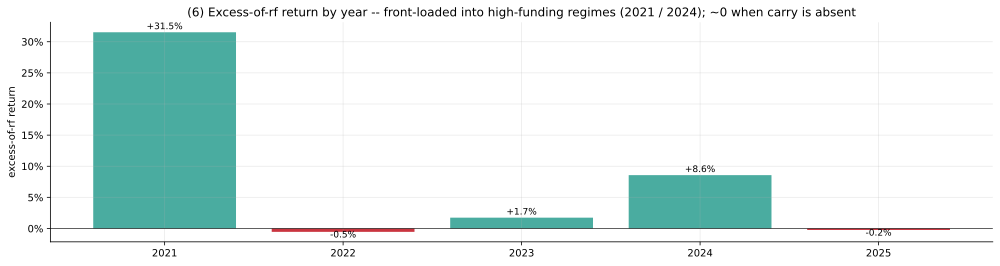

In [15]:
clock = {2021:'~40%',2022:'~0%',2023:'~0%',2024:'~16%',2025:'~3%',2026:'n/a'}
prof = PY[['net %','rf %','excess %','Sharpe']].copy()
prof.insert(0, 'median funding APR (regime clock)', [clock.get(y,'') for y in prof.index])
print('REGIME PROFILE -- excess (live) vs the carry-supply clock (literal, regime_atlas)')
print(prof.to_string())

fig,ax = plt.subplots(figsize=(14,3.8))
yrs = [y for y in PY.index if y in clock and clock[y]!='n/a']
vals = [PY.loc[y,'excess %'] for y in yrs]
cols = [TEAL if v>=0 else RED for v in vals]
ax.bar([str(y) for y in yrs], vals, color=cols, alpha=0.85)
for x,v in zip(range(len(yrs)), vals): ax.text(x, v + (0.5 if v>=0 else -0.9), f'{v:+.1f}%', ha='center', fontsize=9)
ax.axhline(0, color='k', lw=0.6); ax.set_ylabel('excess-of-rf return')
ax.yaxis.set_major_formatter(pct)
ax.set_title('(6) Excess-of-rf return by year -- front-loaded into high-funding regimes (2021 / 2024); ~0 when carry is absent')
plt.tight_layout(); plt.show()

**Diversification (literal, `research/regime_atlas/`).** Monthly correlation of the carry book to
the canonical trend / momentum / dispersion sleeves is **<= 0.35** --- the regime-atlas sleeve audit
found nothing that beats carry-alone Sharpe, only a mild flat-year smoother, and no dynamic allocation
that beats holding carry statically. So the book is a low-correlation return stream whose *timing* is
dictated by the funding-supply regime, not by price trend.

## 7. Risks & caveats

- The **2x-cost Sharpe (3.48) is not deflation-robust** (DSR 0.05 at N~143, `multiple_testing/`)
  --- quote it only as a cost-stress figure, never as the headline.
- The **drawdown overlay is validated on ~1 episode** (the 2022 deleveraging); its 2022 exit is most of
  the maxDD and Calmar benefit, so the protection rides on the overlay behaving the same way next time.
- **Capacity binds through overlay exit latency, not price impact** (§8): at scale the all-out 2022 exit
  lags under the 5%-ADV cap and the drawdown protection degrades before the carry does.
- **Execution is assumed taker at ~19bp/side per carry pair and is unvalidated** until a live pilot;
  the 2x-cost column is the stress proxy for fill/slippage error.
- **Regime concentration:** essentially all excess is earned in 2021 and 2024; a multi-year low-leverage
  regime would deliver ~rf, not alpha (by design, but a real return-timing risk for an allocator).
- **Operational assumptions:** Portfolio-Margin accounts on both venues, cross-venue transfers, spot-leg
  borrow availability, and on-venue Earn capture (0.75) --- all modelled, none yet operated live.

## 8. Capacity

**Study literals** (`capacity/capacity.ipynb` + `v7_cross_venue/cross_venue.ipynb`; a 5%-ADV
participation cap, summed venue ADV). The carry itself scales deep --- net bleeds only ~10.3% -> ~8.0%
from \$1M to \$100M because the majors are liquid. What breaks first is the **drawdown protection**:
under the ADV cap the overlay's all-out 2022 exit lags 0 -> ~6 days, so maxDD widens and Calmar
collapses. The **full book (v8.1)** raises the ceiling because it spreads the same notional over more
venue:pair ADV.

In [16]:
capacity = pd.DataFrame([
 ('$1M',   '~10.3%', '~-0.9%', '~11',   'edge and protection both intact'),
 ('$10M',  '~9-10%', 'widening','~5-7',  'overlay exit begins to lag'),
 ('$30M',  '~8-9%',  'wider',  '1.18 (v8.0 breadth) -> 2.17 (v8.1 full book)', 'the ceiling zone; full book roughly doubles Calmar'),
 ('$100M', '~8.0%',  '~-7.6%', '~1.0',  'carry survives, drawdown protection effectively gone'),
], columns=['AUM','net ann','maxDD','Calmar','note'])
print('CAPACITY DECAY  (literals: capacity/ + v7_cross_venue/)')
print(capacity.to_string(index=False))
print('\nverdict: ceiling ~$20-30M for v8.0 (breadth); ~$40M+ for v8.1 (full book).')
print('this run v8.0 avg names %d, deployed %.0f%%; v8.1 avg names %d, deployed %.0f%%'
      % (MJ['results']['1.0x']['avg_names_held'], MJ['results']['1.0x']['pct_days_deployed']*100,
         MJ81['results']['1.0x']['avg_names_held'], MJ81['results']['1.0x']['pct_days_deployed']*100))

CAPACITY DECAY  (literals: capacity/ + v7_cross_venue/)
  AUM net ann    maxDD                                       Calmar                                                 note
  $1M  ~10.3%   ~-0.9%                                          ~11                      edge and protection both intact
 $10M  ~9-10% widening                                         ~5-7                           overlay exit begins to lag
 $30M   ~8-9%    wider 1.18 (v8.0 breadth) -> 2.17 (v8.1 full book)   the ceiling zone; full book roughly doubles Calmar
$100M   ~8.0%   ~-7.6%                                         ~1.0 carry survives, drawdown protection effectively gone

verdict: ceiling ~$20-30M for v8.0 (breadth); ~$40M+ for v8.1 (full book).
this run v8.0 avg names 146, deployed 78%; v8.1 avg names 205, deployed 82%


## 9. Reproduce

```bash
# 1. Backfill + normalise the venues used by the book (idempotent; chunked per day)
uv run python -m scripts.backfill  --source binance          # perps: bars, funding_rate (incl. delisted)
uv run python -m scripts.backfill  --source bybit
uv run python -m scripts.normalize --source binance
uv run python -m scripts.normalize --source bybit

# 2. rf series -- FRED 3-month T-bill (needs FRED_API_KEY in env/.env)
uv run python -m scripts.backfill  --source fred
uv run python -m scripts.normalize --source fred

# 3. THE product backtest (writes results/funding_carry/v8.0/<run>/ + report.html)
uv run python -m src.strategies.funding_carry.v8.backtest --config strategies/funding_carry/v8.yaml
uv run python -m src.strategies.funding_carry.v8.backtest --config strategies/funding_carry/v8.1.yaml   # capacity config

# 4. Rebuild THIS report (executes + writes final_report.ipynb in place from the newest v8.0/v8.1 runs)
uv run python research/funding_carry/final_report/_build_final_report.py
```

All research behind §4/§6/§8 is one `_build_*.py` -> `.ipynb` per folder under `research/funding_carry/`
(and `research/regime_atlas/`), indexed in `research/funding_carry/README.md`.